In [2]:
# Phase 1: Video Processing:-
# 1.1 Extract Frames from a Video:
import cv2

# Read the video file
VideoPath = 'ExtractFrameVideo.mp4'

# Initialize the video capture object
VideoCap = cv2.VideoCapture(VideoPath)

# Get the total number of frames in the video
TotalFrames = int(VideoCap.get(cv2.CAP_PROP_FRAME_COUNT))

# Calculate the frame interval to ensure 6 different frames
FrameInterval = TotalFrames // 6

# Initialize counter for frames
FrameCounter = 0

# Loop to extract the first 6 frames
i = 0
while i < 6:
    # Move to the desired frame
    FrameCounter += FrameInterval
    VideoCap.set(cv2.CAP_PROP_POS_FRAMES, FrameCounter)

    # Read frame
    success, Frame = VideoCap.read()

    # Save the extracted frame as image file
    cv2.imwrite(f'Frame_{i+1}.png', Frame)
    print(f"Frame {i+1} is extracted")
    i += 1

# Release the video capture object
VideoCap.release()

Frame 1 is extracted
Frame 2 is extracted
Frame 3 is extracted
Frame 4 is extracted
Frame 5 is extracted
Frame 6 is extracted


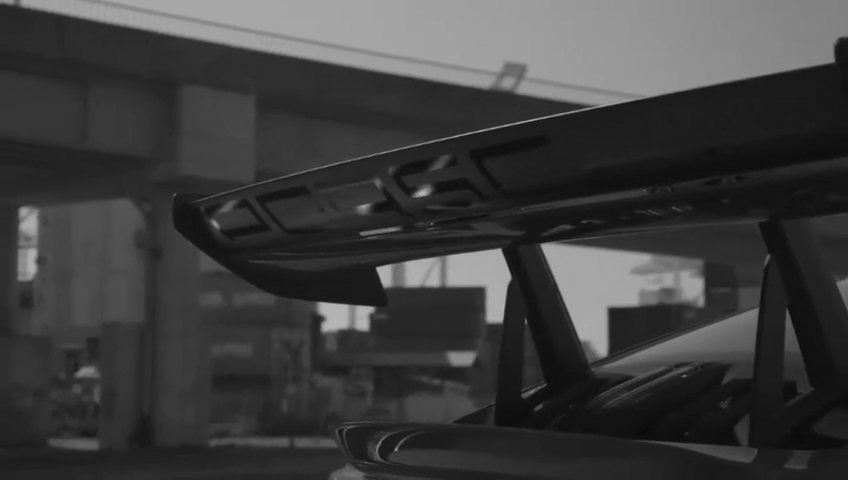

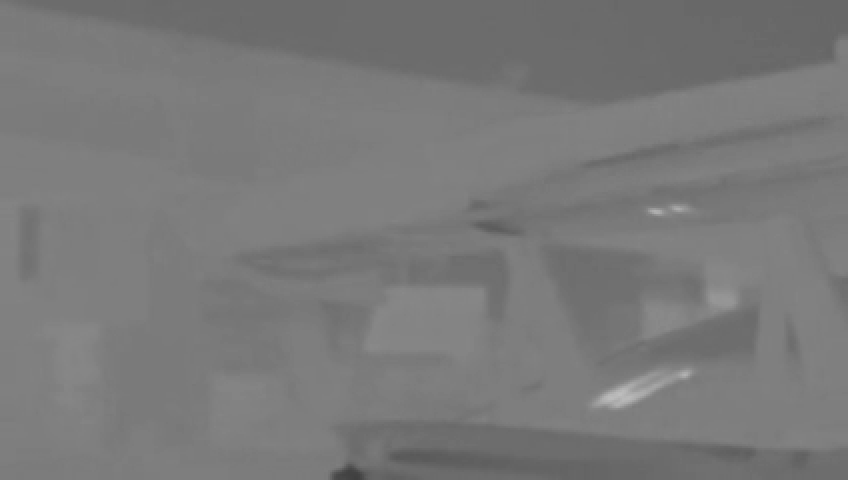

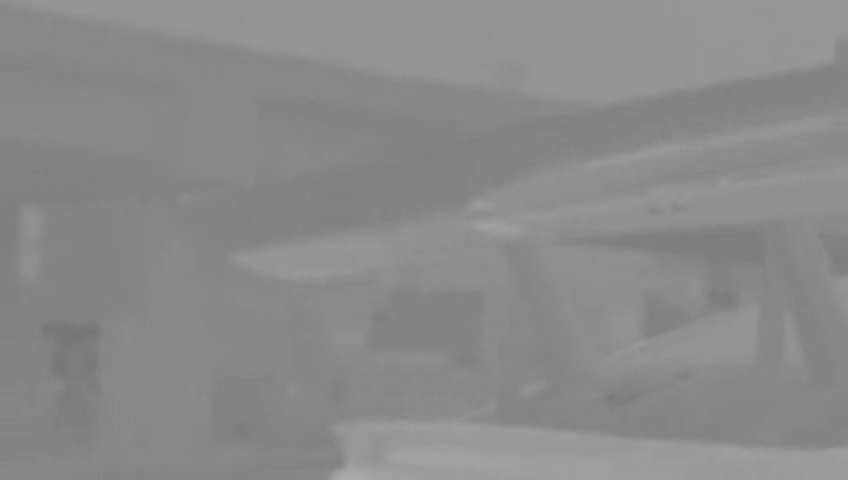

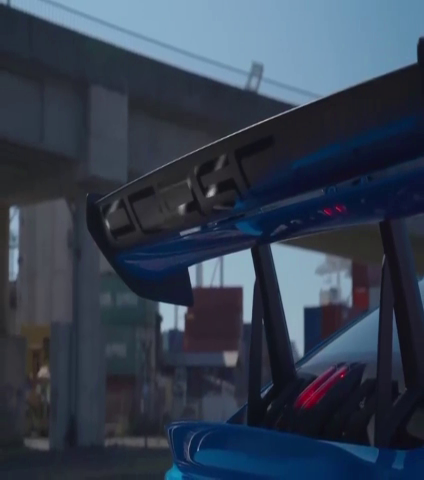

Resolutions before subsampling:
Y Component: (480, 848)
Cb Component: (480, 848)
Cr Component: (480, 848)

Resolutions after subsampling:
Y Component: (480, 424)
Cb Component: (480, 424)
Cr Component: (480, 424)


In [3]:
# Phase 1: Video Processing:-
#  1.2 Video Compression- Chroma Subsampling:
import cv2
from google.colab.patches import cv2_imshow

# Read the first frame
Frame = cv2.imread('Frame_1.png')

# a) Convert frame from RGB to YCbCr colorspace
YCbCr_Frame = cv2.cvtColor(Frame, cv2.COLOR_BGR2YCrCb)

# Split YCbCr components
Y, Cb, Cr = cv2.split(YCbCr_Frame)

# b) Display Y, Cb, and Cr components in 3 separate images
cv2_imshow(Y)
cv2_imshow(Cb)
cv2_imshow(Cr)
cv2.waitKey(0)
cv2.destroyAllWindows()

# c) Apply 4:2:2 subsampling to the YCbCr components
Cb_Subsampled = cv2.resize(Cb, (Cb.shape[1] // 2, Cb.shape[0]))
Cr_Subsampled = cv2.resize(Cr, (Cr.shape[1] // 2, Cr.shape[0]))

# Resize Y component to match the size of the subsampled components
Y_Resized = cv2.resize(Y, (Cb_Subsampled.shape[1], Cb_Subsampled.shape[0]))

# d) Display the compressed frame after subsampling
CompressedFrame = cv2.merge((Y_Resized, Cb_Subsampled, Cr_Subsampled))
cv2_imshow(cv2.cvtColor(CompressedFrame, cv2.COLOR_YCrCb2BGR))
cv2.waitKey(0)
cv2.destroyAllWindows()

# e) Print resolutions of the 3 components before and after subsampling
print("Resolutions before subsampling:")
print("Y Component:", Y.shape)
print("Cb Component:", Cb.shape)
print("Cr Component:", Cr.shape)
print("\nResolutions after subsampling:")
print("Y Component:", Y_Resized.shape)
print("Cb Component:", Cb_Subsampled.shape)
print("Cr Component:", Cr_Subsampled.shape)

In [5]:
# Phase 1: Video Processing:-
# 1.3 Motion Detection:
import cv2

# Read the video file
VidPath = 'MotionDetectionVid.mp4'

# Initialize the video capture object
VidCap = cv2.VideoCapture(VidPath)

# Get the first frame
success, PrevFrame = VidCap.read()

# Get the frame width and height
WidthFrame = int(VidCap.get(cv2.CAP_PROP_FRAME_WIDTH))
HeightFrame = int(VidCap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Define the codec and create VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'MP4V')
NewVideo = cv2.VideoWriter('New_Video_Output.mp4', fourcc, 30.0, (WidthFrame, HeightFrame), isColor=False)

# Loop through frames and perform motion detection
while True:
    # Read the next frame
    success, CurrFrame = VidCap.read()
    if not success:
        break

    # Convert frames to grayscale
    PreviousFrame_grayscale = cv2.cvtColor(PrevFrame, cv2.COLOR_BGR2GRAY)
    CurrentFrame_grayscale = cv2.cvtColor(CurrFrame, cv2.COLOR_BGR2GRAY)

    # Calculate absolute difference between consecutive frames
    Frame_Differencing  = cv2.absdiff(PreviousFrame_grayscale, CurrentFrame_grayscale)

    # Threshold the absolute difference to identify motion
    _, ThresholdedFrame = cv2.threshold(Frame_Differencing, 30, 255, cv2.THRESH_BINARY)

    # Write the thresholded frame to the output video
    NewVideo.write(ThresholdedFrame)

    # Update previous frame
    PrevFrame = CurrFrame.copy()

# Release video objects
VidCap.release()
NewVideo.release()
cv2.destroyAllWindows()

In [4]:
# Phase 2: Audio Processing:-
# 2.1 Extract Audio from a video:
# using moviepy library
!pip install moviepy

In [6]:
# Phase 2: Audio Processing:-
# 2.1 Extract Audio from a video:

# using moviepy library
from moviepy.editor import VideoFileClip

# Read the same video file used in phase 1
PathVideo = 'MotionDetectionVid.mp4'

# Load the video clip
VideoClip = VideoFileClip(PathVideo)

# Extract audio from the video clip
AudioClip = VideoClip.audio

# Choose the output audio file format 'mp3'
AudioPath_Output = 'Extracted_Audio.mp3'

# Save the extracted audio clip as a MP3 file
AudioClip.write_audiofile(AudioPath_Output, codec='libmp3lame')

# Close the video and audio clips
VideoClip.close()
AudioClip.close()

MoviePy - Writing audio in Extracted_Audio.mp3


MoviePy - Done.


In [7]:
# Phase 2: Audio Processing:-
# 2.2 Audio Filtering:
# Pitch: making a singer's voice sound like a chipmunk (higher pitch) or a deep voice (lower pitch)
# Fade In: is a gradual increase in volume at the beginning of a piece of audio
# Fade Out:  is the opposite of a fade in. It's a gradual decrease in volume at the end of a piece of audio